**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: ENMANUEL ABREU
*   MATRÍCULA: A01841472

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [240]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [241]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [242]:
# Cargar el archivo CSV desde la ruta correspondiente en Google Drive
cardio_df = pd.read_csv('/content/drive/MyDrive/Ciencia de Datos/Semana 5/heart_disease.csv')

# Utilizar ID como índice del dataframe
cardio_df.set_index('id', inplace=True)

# Mostrar el resumen de las columnas y sus tipos de datos
cardio_df.info()

# Contar los valores únicos de cada columna
cardio_df.nunique()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


*   **7 columnas numéricas:** 2 de tipo int64 y 5 de tipo float64.
*   **8 columnas de texto:** de tipo object.
*   **918** valores únicos


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [243]:
# Revisión de las variables numéricas con 10 o menos valores únicos
for columna in cardio_df.select_dtypes(include='number').columns:
    if cardio_df[columna].nunique() <= 10:
        print(columna, sorted(cardio_df[columna].dropna().unique()))

ca [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
num [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [244]:
# Definir las categorías y su orden
orden_ca = [0, 1, 2, 3]
orden_num = [0, 1, 2, 3, 4]

# Convertir las variables a categóricas ordinales
cardio_df['ca'] = pd.Categorical(
    cardio_df['ca'],
    categories=orden_ca,
    ordered=True
)

cardio_df['num'] = pd.Categorical(
    cardio_df['num'],
    categories=orden_num,
    ordered=True
)

# Revisión de los tipos de datos después de la conversión
cardio_df[['ca', 'num']].dtypes

,0
ca,category
num,category


In [245]:
# Comprobar que ambas variables sean categóricas
print(cardio_df[['ca', 'num']].dtypes)

# Revisar las categorías y su orden
print("Categorías de ca:", cardio_df['ca'].cat.categories.tolist())
print("Categorías de num:", cardio_df['num'].cat.categories.tolist())

ca     category
num    category
dtype: object
Categorías de ca: [0, 1, 2, 3]
Categorías de num: [0, 1, 2, 3, 4]


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [246]:
# Estadísticas descriptivas de las variables numéricas

# Seleccionat las variables numéricas
numericas = cardio_df.select_dtypes(include=np.number)

# Obtener las estadísticas descriptivas
estadisticas_num = numericas.describe().T

# Agregar el sesgo y la curtosis
estadisticas_num['sesgo'] = numericas.skew()
estadisticas_num['curtosis'] = numericas.kurtosis()

# Mostrar resultados
estadisticas_num

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


In [247]:
# Estadísticas descriptivas de las variables categóricas

# Seleccionar las variables categóricas
categoricas = cardio_df.select_dtypes(include=['object', 'category'])

# Mostrar las estadísticas descriptivas
categoricas.describe().T

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309,4,0,181
thal,434,3,normal,196
num,918,5,0,411


In [248]:
# Tablas de frecuencia de las variables categóricas

# Mostrar la frecuencia absoluta y relativa de cada categoría
for columna in categoricas.columns:
    print(f'\nFrecuencias de {columna}:')

    frecuencias = categoricas[columna].value_counts(
        dropna=False
    ).to_frame(name='Frecuencia')

    frecuencias['Porcentaje'] = (
        categoricas[columna].value_counts(dropna=False, normalize=True) * 100
    ).round(2)

    print(frecuencias)



Frecuencias de sex:
        Frecuencia  Porcentaje
sex                           
Male           724       78.87
Female         194       21.13

Frecuencias de origin:
               Frecuencia  Porcentaje
origin                               
Cleveland             304       33.12
Hungary               292       31.81
VA Long Beach         200       21.79
Switzerland           122       13.29

Frecuencias de cp:
                 Frecuencia  Porcentaje
cp                                     
asymptomatic            495       53.92
non-anginal             204       22.22
atypical angina         174       18.95
typical angina           45        4.90

Frecuencias de fbs:
       Frecuencia  Porcentaje
fbs                          
False         691       75.27
True          138       15.03
NaN            89        9.69

Frecuencias de restecg:
                  Frecuencia  Porcentaje
restecg                                 
normal                   551       60.02
lv hypertrophy          

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [249]:
# Calcular el porcentaje de valores faltantes por columna
faltantes_pct = (cardio_df.isnull().mean() * 100).sort_values(
    ascending=False
)

print(faltantes_pct.round(2))


ca          66.34
thal        52.72
slope       33.55
fbs          9.69
oldpeak      6.75
trestbps     6.43
thalch       5.99
exang        5.99
chol         3.27
sex          0.00
origin       0.00
cp           0.00
age          0.00
restecg      0.00
num          0.00
dtype: float64


In [250]:
# Identificar las columnas que superan el 30 % de valores faltantes
columnas_eliminar = faltantes_pct[faltantes_pct > 30].index

# Eliminar esas columnas del dataframe
cardio_df.drop(columns=columnas_eliminar, inplace=True)

# Comprobar las columnas restantes
print("Columnas eliminadas:", columnas_eliminar.tolist())
print("Dimensiones del dataframe:", cardio_df.shape)


Columnas eliminadas: ['ca', 'thal', 'slope']
Dimensiones del dataframe: (918, 12)


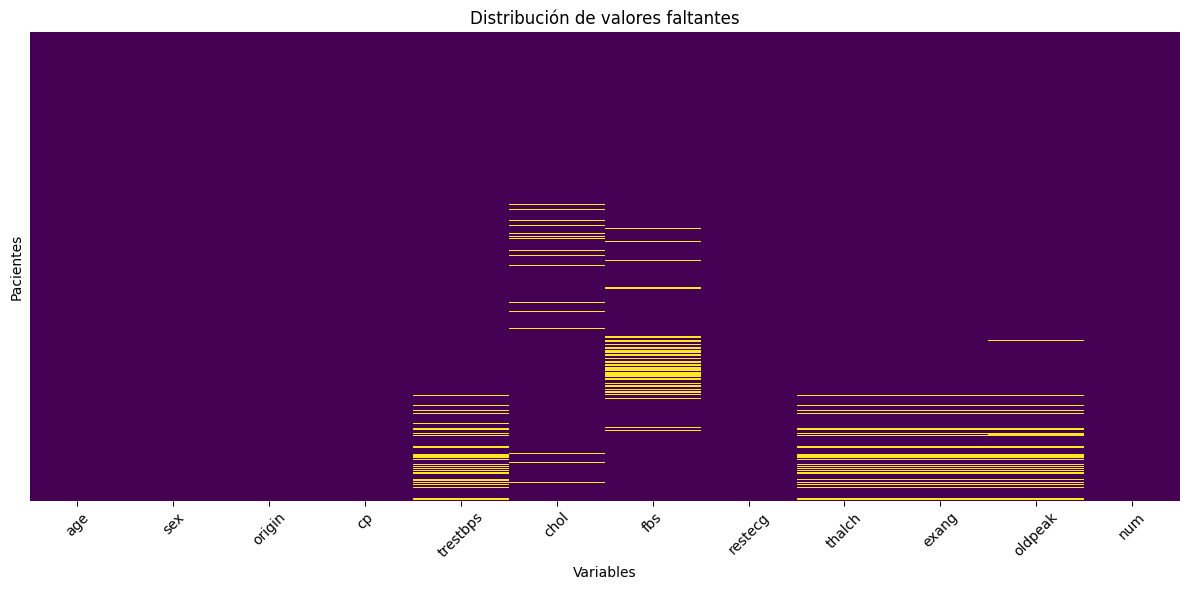

In [251]:
# Crear el mapa de calor de los valores faltantes
plt.figure(figsize=(12, 6))

sns.heatmap(
    cardio_df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Distribución de valores faltantes')
plt.xlabel('Variables')
plt.ylabel('Pacientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [252]:
# Seleccionar las columnas que todavía tienen valores faltantes
columnas_con_faltantes = cardio_df.columns[
    cardio_df.isnull().any()
]

# Contar las ausencias simultáneas entre cada par de variables
for i, col1 in enumerate(columnas_con_faltantes):
    for col2 in columnas_con_faltantes[i + 1:]:
        cantidad = (
            cardio_df[col1].isnull() &
            cardio_df[col2].isnull()
        ).sum()

        if cantidad > 0:
            print(f'{col1} y {col2}: {cantidad} pacientes')


trestbps y chol: 3 pacientes
trestbps y fbs: 1 pacientes
trestbps y thalch: 55 pacientes
trestbps y exang: 55 pacientes
trestbps y oldpeak: 55 pacientes
chol y thalch: 3 pacientes
chol y exang: 3 pacientes
chol y oldpeak: 3 pacientes
fbs y oldpeak: 4 pacientes
thalch y exang: 55 pacientes
thalch y oldpeak: 54 pacientes
exang y oldpeak: 54 pacientes


**Hallazgos:** Los pacientes presentan la mayor cantidad de valores faltantes simultáneamente en las variables **trestbps**, **thalch**, **exang** y **oldpeak**.

Estas variables incluyen mediciones relacionadas con la evaluación cardíaca y las pruebas de esfuerzo. Si una prueba no se realiza, no se completa o sus resultados no se registran, varias mediciones pueden faltar al mismo tiempo.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [253]:
# Crear los grupos y definir las funciones de análisis

# True indica que falta thalch; False indica que está disponible
BM_MV = cardio_df['thalch'].isnull()

# Contamos los pacientes de cada grupo
print("Con thalch faltante:", BM_MV.sum())
print("Sin thalch faltante:", (~BM_MV).sum())


Con thalch faltante: 55
Sin thalch faltante: 863


*   Para las siguientes hipótesis voy a utilizar el nivel de significancia de 0.05
*   En el archivo hay **55** pacientes con thalch faltante y **863** sin thalch faltantes



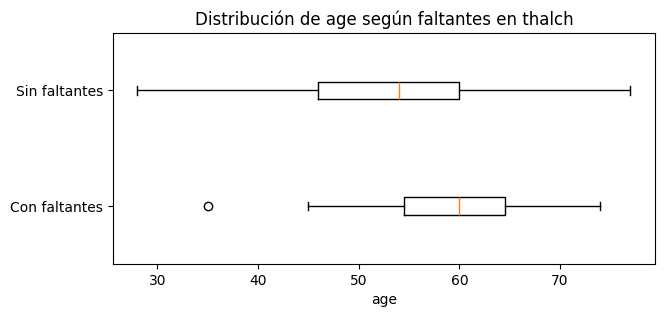

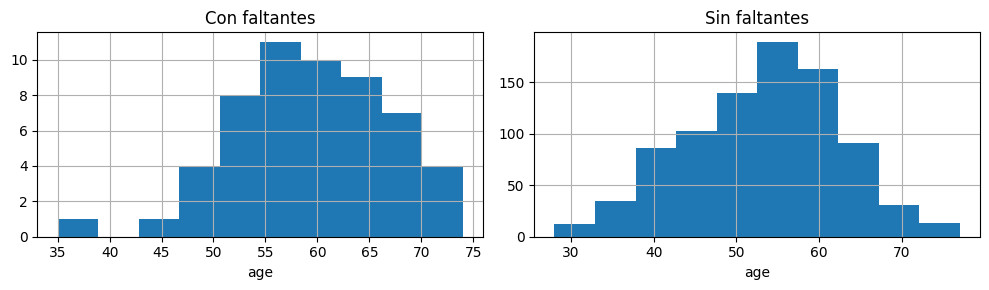

Media con faltantes: 59.42
Media sin faltantes: 53.16
p-value: 4.115876441882053e-07


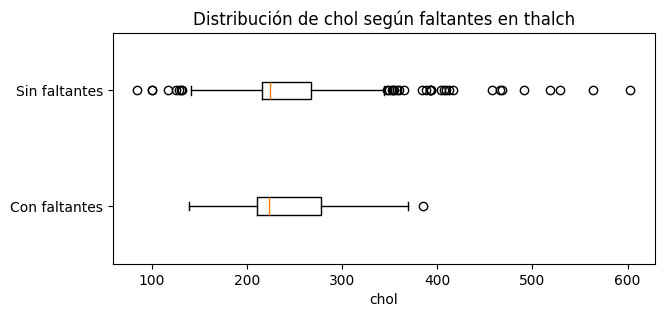

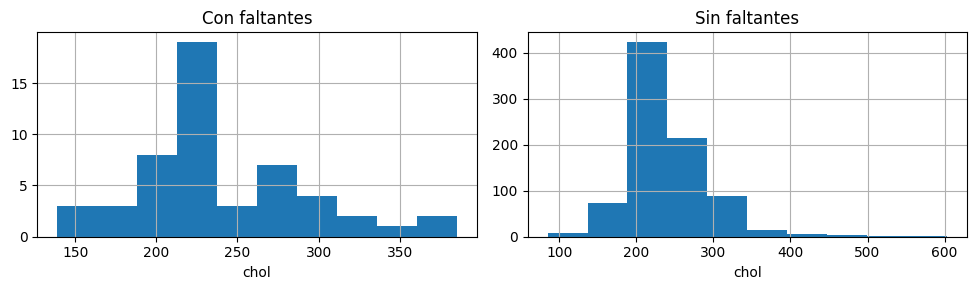

Media con faltantes: 239.58
Media sin faltantes: 242.35
p-value: 0.7104715640105805


In [254]:
# Análisis de las variables numéricas: age y chol
from scipy.stats import ttest_ind

def Diagnose_MV_Numerical(df, columna, BM_MV):
    # Comparar las distribuciones de ambos grupos
    grupo_faltante = df.loc[BM_MV, columna].dropna()
    grupo_completo = df.loc[~BM_MV, columna].dropna()

    # Diagramas de caja
    plt.figure(figsize=(7, 3))
    plt.boxplot(
        [grupo_faltante, grupo_completo],
        tick_labels=['Con faltantes', 'Sin faltantes'],
        vert=False
    )
    plt.xlabel(columna)
    plt.title(f'Distribución de {columna} según faltantes en thalch')
    plt.show()

    # Histogramas
    plt.figure(figsize=(10, 3))

    plt.subplot(1, 2, 1)
    grupo_faltante.hist()
    plt.title('Con faltantes')
    plt.xlabel(columna)

    plt.subplot(1, 2, 2)
    grupo_completo.hist()
    plt.title('Sin faltantes')
    plt.xlabel(columna)

    plt.tight_layout()
    plt.show()

    # Comparación de las medias
    resultado = ttest_ind(
        grupo_faltante,
        grupo_completo,
        equal_var=False
    )

    print("Media con faltantes:", round(grupo_faltante.mean(), 2))
    print("Media sin faltantes:", round(grupo_completo.mean(), 2))
    print("p-value:", resultado.pvalue)

# Análisis de la edad
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV)

# Análizamos el colesterol
Diagnose_MV_Numerical(cardio_df, 'chol', BM_MV)

**Conclusiones:**
*   **Edad (age)**: el valor p es menor que 0.05. Existe una diferencia estadísticamente significativa entre los grupos; los pacientes con thalch faltante tienen una edad promedio mayor.
*   **Colesterol (chol)**: el valor p es mayor que 0.05. No encontramos evidencia estadística suficiente para afirmar que las medias sean diferentes.









Porcentajes por grupo:
restecg        lv hypertrophy  normal  st-t abnormality
thalch                                                 
Con faltantes           12.73   34.55             52.73
Sin faltantes           20.97   61.65             17.38


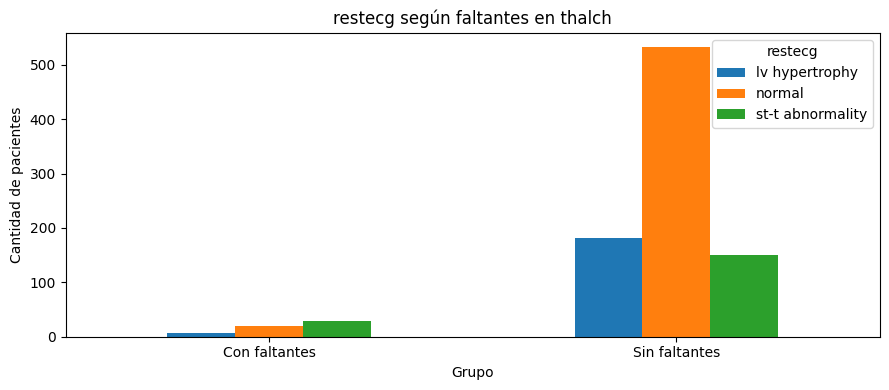

p-value de chi-cuadrado: 1.1472889573985424e-09
Frecuencias esperadas:
restecg        lv hypertrophy      normal  st-t abnormality
thalch                                                     
Con faltantes       11.263617   33.011983         10.724401
Sin faltantes      176.736383  517.988017        168.275599
Porcentajes por grupo:
cp             asymptomatic  atypical angina  non-anginal  typical angina
thalch                                                                   
Con faltantes         47.27            12.73        32.73            7.27
Sin faltantes         54.35            19.35        21.55            4.75


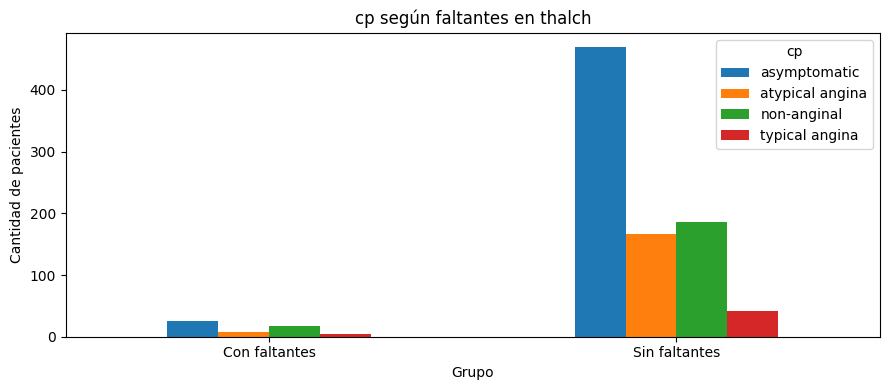

p-value de chi-cuadrado: 0.15420097177251701
Frecuencias esperadas:
cp             asymptomatic  atypical angina  non-anginal  typical angina
thalch                                                                   
Con faltantes     29.656863        10.424837    12.222222        2.696078
Sin faltantes    465.343137       163.575163   191.777778       42.303922


In [255]:
# Análisis de las variables categóricas: restecg y cp
from scipy.stats import chi2_contingency

def Diagnose_MV_Categorical(df, columna, BM_MV):
    # Comparamos las frecuencias de cada categoría
    tabla = pd.crosstab(
        BM_MV.map({True: 'Con faltantes', False: 'Sin faltantes'}),
        df[columna]
    )

    # Mostramos las frecuencias relativas dentro de cada grupo
    print("Porcentajes por grupo:")
    print((tabla.div(tabla.sum(axis=1), axis=0) * 100).round(2))

    # Gráfico de barras
    tabla.plot(kind='bar', figsize=(9, 4))
    plt.title(f'{columna} según faltantes en thalch')
    plt.xlabel('Grupo')
    plt.ylabel('Cantidad de pacientes')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Prueba de chi-cuadrado
    chi2, p_value, grados_libertad, esperados = chi2_contingency(tabla)

    print("p-value de chi-cuadrado:", p_value)
    print("Frecuencias esperadas:")
    print(pd.DataFrame(esperados, index=tabla.index, columns=tabla.columns))

    # Análisis de electrocardiograma en reposo
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV)

# Análisis del tipo de dolor torácico
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV)


**Conclusiones:**

En **restecg**, las distribuciones son diferentes entre los grupos. Entre los pacientes con thalch faltante, aproximadamente el **52.7%** presenta una anomalía ST-T, frente al **17.4%** de quienes tienen thalch disponible. Por tanto, la ausencia de la frecuencia cardíaca máxima está asociada con el resultado del electrocardiograma en reposo.

En **cp**, aunque se observan diferencias en algunos porcentajes, la prueba no alcanza el nivel de significancia de 0.05. No tenemos evidencia suficiente para concluir que la distribución del tipo de dolor torácico esté relacionada con los faltantes de thalch.

**¿MCAR o MAR?**

Los resultados aportan evidencia en contra de que los faltantes de thalch sean MCAR, porque su presencia está asociada con age y restecg. Por ello, **MAR es una hipótesis razonable** de trabajo, ya que la ausencia podría depender de características observadas de los pacientes o del centro donde fueron estudiados.

Para distinguirlos definitivamente se necesitaría información adicional sobre cómo se recopilaron los datos y por qué algunas mediciones no se registraron.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [256]:
# Imputar los valores faltantes por grupo

# Variables numéricas que vamos a imputar con la mediana
numericas = ['thalch', 'trestbps', 'oldpeak']

for columna in numericas:
    cardio_df[columna] = cardio_df.groupby(
        'restecg', dropna=False
    )[columna].transform(
        lambda x: x.fillna(x.median())
    )

# Imputamos exang con la moda de cada grupo
cardio_df['exang'] = cardio_df.groupby(
    'restecg', dropna=False
)['exang'].transform(
    lambda x: x.fillna(
        x.mode().iloc[0] if not x.mode().empty else np.nan
    )
)

# Comprobamos los valores faltantes de las variables imputadas
print(cardio_df[['thalch', 'trestbps', 'exang', 'oldpeak']].isnull().sum())


thalch      0
trestbps    0
exang       0
oldpeak     0
dtype: int64


/tmp/ipykernel_108532/1432190427.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lambda x: x.fillna(


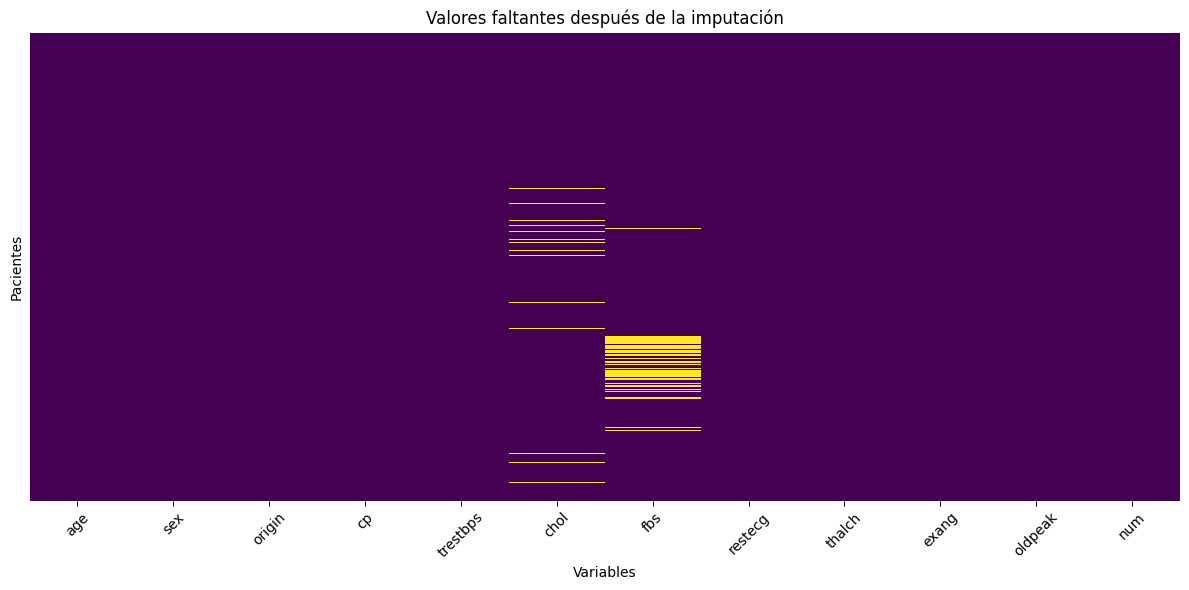

In [257]:
# Visualizar los valores faltantes después de la imputación
plt.figure(figsize=(12, 6))

sns.heatmap(
    cardio_df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Valores faltantes después de la imputación')
plt.xlabel('Variables')
plt.ylabel('Pacientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [258]:
# Revisar cuántos valores faltantes quedan en las variables imputadas
print(cardio_df[['thalch', 'trestbps', 'exang', 'oldpeak']].isnull().sum())

# Revisar todos los valores faltantes restantes
print(cardio_df.isnull().sum())


thalch      0
trestbps    0
exang       0
oldpeak     0
dtype: int64
age          0
sex          0
origin       0
cp           0
trestbps     0
chol        30
fbs         89
restecg      0
thalch       0
exang        0
oldpeak      0
num          0
dtype: int64


**Nota:** Después de ejecutar el código, las variables imputadas presentan cero valores faltantes, siempre que cada grupo tenga valores disponibles para calcular su mediana o moda. El mapa de calor permitirá verificarlo de forma visual.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [259]:
# Revisión de las columnas que todavía tienen valores faltantes
faltantes = cardio_df.isnull().sum()
print(faltantes[faltantes > 0])

chol    30
fbs     89
dtype: int64


In [260]:
from pandas.api.types import is_numeric_dtype

# Identificar las columnas que aún tienen valores faltantes
columnas_faltantes = cardio_df.columns[
    cardio_df.isnull().any()
]

# Imputar cada columna con una estadística general
for columna in columnas_faltantes:

    # Elección de estrategia según el tipo de variable
    if is_numeric_dtype(cardio_df[columna]):
        estrategia = 'median'
    else:
        estrategia = 'most_frequent'

    # SimpleImputer
    imputer = SimpleImputer(strategy=estrategia)

    cardio_df[columna] = imputer.fit_transform(
        cardio_df[[columna]]
    ).ravel()

    print(f'{columna}: estrategia = {estrategia}')

# Comprobar valores faltantes
print("\nValores faltantes por columna:")
print(cardio_df.isnull().sum())

total_faltantes = cardio_df.isnull().sum().sum()

print("Total de valores faltantes:", total_faltantes)

if total_faltantes == 0:
    print("La imputación se completó correctamente.")
else:
    print("Todavía existen valores por revisar.")


chol: estrategia = median
fbs: estrategia = most_frequent

Valores faltantes por columna:
age         0
sex         0
origin      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
dtype: int64
Total de valores faltantes: 0
La imputación se completó correctamente.


**Justificación de las estrategias**

*   **Mediana:** Es resistente a valores extremos y resulta apropiada para mediciones clínicas como el colesterol.
*   **Moda:** Sustituye los faltantes por la categoría más frecuente y conserva valores válidos de la variable como en el caso de fbs o restecg
*   **Media:** Aunque puede ser útil en variables numéricas con distribuciones relativamente simétricas y sin valores extremos importantes, considero mejor utilizar la mediana para las variables clínicas.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

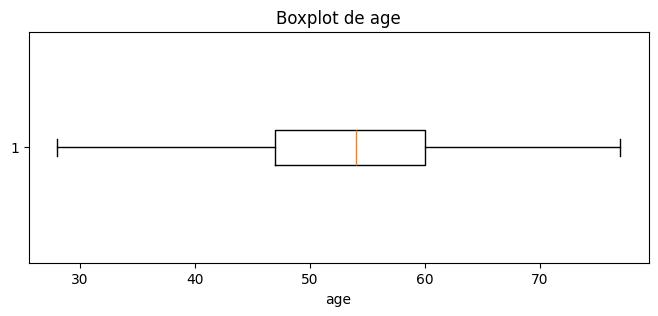

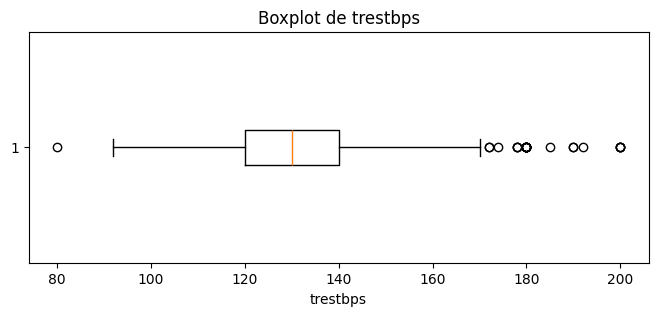

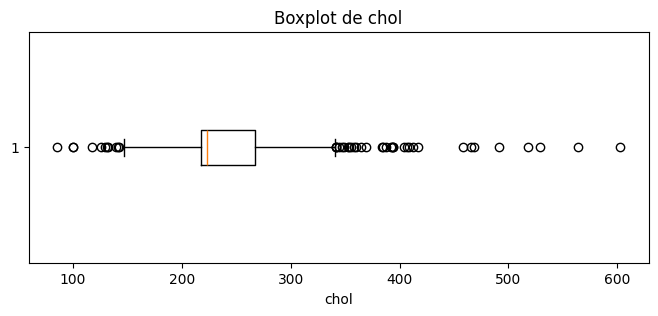

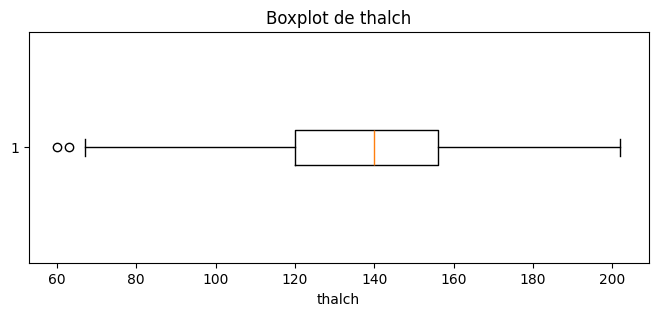

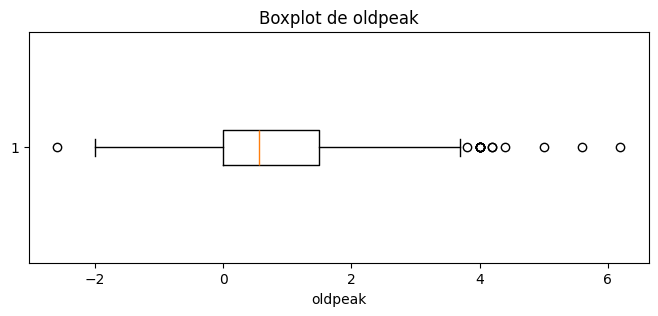

In [261]:
# Selección de las variables numéricas
numericas = cardio_df.select_dtypes(include=np.number).columns

# Creación de boxplot para cada variable numérica
for columna in numericas:
    plt.figure(figsize=(8, 3))

    # Guardar el objeto que devuelve el boxplot
    bp = plt.boxplot(cardio_df[columna].dropna(), vert=False)

    plt.title(f'Boxplot de {columna}')
    plt.xlabel(columna)
    plt.show()


In [262]:
# Obtener los valores atípicos directamente del boxplot
for columna in numericas:
    datos = cardio_df[columna].dropna()

    # Creación del boxplot y guardamos el objeto
    bp = plt.boxplot(datos, vert=False)

    # Extracción de los valores representados como atípicos
    valores_atipicos = bp['fliers'][0].get_xdata()

    plt.close()

    print(f'\nVariable: {columna}')
    print('Cantidad de valores atípicos:', len(valores_atipicos))
    print('Valores atípicos:', valores_atipicos)



Variable: age
Cantidad de valores atípicos: 0
Valores atípicos: []

Variable: trestbps
Cantidad de valores atípicos: 27
Valores atípicos: [ 80. 172. 180. 200. 174. 178. 192. 180. 178. 180. 190. 180. 180. 180.
 180. 200. 180. 180. 180. 200. 185. 200. 180. 178. 172. 180. 190.]

Variable: chol
Cantidad de valores atípicos: 44
Valores atípicos: [141. 126. 131. 132. 129. 100.  85. 117. 100. 142. 139. 354. 353. 417.
 360. 407. 564. 394. 409. 342. 358. 412. 468. 365. 344. 394. 347. 466.
 529. 392. 355. 603. 342. 404. 518. 388. 491. 342. 393. 458. 384. 349.
 369. 385.]

Variable: thalch
Cantidad de valores atípicos: 2
Valores atípicos: [60. 63.]

Variable: oldpeak
Cantidad de valores atípicos: 16
Valores atípicos: [-2.6  6.2  4.   5.6  4.   4.2  4.2  3.8  4.4  4.   4.   5.   4.   4.
  4.   4. ]


9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [263]:
# Primer y tercer cuartil
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Calcular los límites para identificar valores atípicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)


Q1: 120.0
Q3: 140.0
IQR: 20.0
Límite inferior: 90.0
Límite superior: 170.0


In [264]:
# Filtrar los valores atípicos de trestbps
atipicos_trestbps = cardio_df[
    (cardio_df['trestbps'] < limite_inferior) |
    (cardio_df['trestbps'] > limite_superior)
]['trestbps']

print("Cantidad de valores atípicos:", len(atipicos_trestbps))
print(atipicos_trestbps.sort_values())


Cantidad de valores atípicos: 27
id
645     80.0
15     172.0
855    172.0
173    174.0
214    178.0
780    178.0
184    178.0
202    180.0
570    180.0
485    180.0
388    180.0
476    180.0
648    180.0
84     180.0
376    180.0
232    180.0
728    180.0
596    180.0
890    180.0
701    185.0
897    190.0
339    190.0
189    192.0
127    200.0
549    200.0
681    200.0
702    200.0
Name: trestbps, dtype: float64


In [265]:
# Comparación de métodos
print("Cantidad según boxplot:", len(atipicos_boxplot))
print("Cantidad según IQR:", len(atipicos_trestbps))

print(
    "¿Coinciden los valores?",
    np.array_equal(
        np.sort(atipicos_boxplot),
        np.sort(atipicos_trestbps.to_numpy())
    )
)

Cantidad según boxplot: 27
Cantidad según IQR: 27
¿Coinciden los valores? True


Ambos resultados **coinciden.**

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [266]:
# Guardar la cantidad de registros antes de eliminar los atípicos
filas_antes = len(cardio_df)

# Conservar los registros dentro de los límites del IQR
cardio_df = cardio_df[
    (cardio_df['trestbps'] >= limite_inferior) &
    (cardio_df['trestbps'] <= limite_superior)
].copy()

# Comparar la cantidad de registros
print("Registros antes:", filas_antes)
print("Registros después:", len(cardio_df))
print("Registros eliminados:", filas_antes - len(cardio_df))


Registros antes: 918
Registros después: 891
Registros eliminados: 27


Se eliminaron **27** registros.

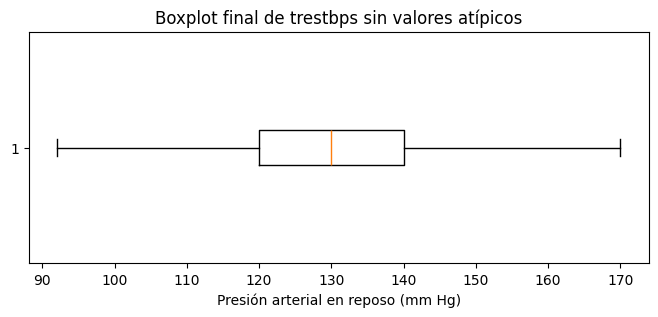

In [267]:
# Boxplot final
plt.figure(figsize=(8, 3))

plt.boxplot(cardio_df['trestbps'].dropna(), vert=False)

plt.title('Boxplot final de trestbps sin valores atípicos')
plt.xlabel('Presión arterial en reposo (mm Hg)')
plt.show()


Google. (2026). Gemini (basado en Gemini 2.5) [Modelo de lenguaje grande], utilizado para la depuración y optimización del código. https://gemini.google.com/